
# WorkShop1

**DNNs en datos tabulares**

**Parte 1) Modelo de Regresion del precio de viviendas**

Problema de **Regresion (Finding a value)**: predecir el precio de una vivienda (`price`).

 **Objetivos**
- Explorar y validar datos tabulares.
- Separar entrenamiento, validación y prueba sin fuga de información (*data leakage*).
- Escalar variables numéricas.
- Construir una red densa .
- Comprender pérdida, optimizador, épocas, mini-lotes y semillas.
- Interpretar curvas de aprendizaje y diagnosticar subajuste/sobreajuste.
- Comparar anchura, profundidad, y medidas de *dropout* y regularización L2.
- Usar Métricas: .
- Examinar importancia por permutación.

**Archivo esperado:** `kc_house_data_yr.xlsx`, en esta misma carpeta.


In [28]:
# %pip install seaborn openpyxl   # ya están instaladas en el entorno .venv del proyecto

## 1. Variables


**Dataset Description**

This dataset contains house sale prices for King County, which includes Seattle.
It includes homes sold between May 2014 and May 2015.
21 columns. (features)
21613 rows.
Features or Columns:

`id`: Unique ID for each home sold

`date`: Date of the home sale

`price`: Price of each home sold

`bedrooms`: Number of bedrooms

`bathrooms`: Number of bathrooms, where .5 accounts for a room with a toilet but no shower

`sqft_living`: Square footage of the apartments interior living space

`sqft_lot`: Square footage of the land space

`floors`: Number of floors

`waterfront`: - A dummy variable for whether the apartment was overlooking the waterfront or not

`view`: An index from 0 to 4 of how good the view of the property was

`condition`: - An index from 1 to 5 on the condition of the apartment,

`grade`: An index from 1 to 13, where 1-3 falls short of building construction and design, 7 has an average level of construction and design, and 11-13 have a high quality level of construction and design.

`sqft_above`: The square footage of the interior housing space that is above ground level

`sqft_basement`: The square footage of the interior housing space that is below ground level

`yr_built`: The year the house was initially built

`yr_renovated`: The year of the house’s last renovation

`zipcode`: What zipcode area the house is in

`lat`: Lattitude

`long`: Longitude

`sqft_living15`: The square footage of interior housing living space for the nearest 15 neighbors

`sqft_lot15`: The square footage of the land lots of the nearest 15 neighbors


In [29]:
# Análisis y manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Red neuronal
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

# Preparación de los datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Métricas de regresión
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponibles: []


In [30]:
from pathlib import Path

ruta_archivo = Path("kc_house_data_yr.xlsx")   # el archivo está en la misma carpeta del notebook

housePrices = pd.read_excel(ruta_archivo)

print("Número de viviendas:", len(housePrices))
print("Número de columnas:", len(housePrices.columns))

display(housePrices.head())

Número de viviendas: 21613
Número de columnas: 21


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [31]:
display(housePrices.tail())

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
21608,263000018,20140521,360000,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223,400000,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623,402101,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116,400000,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287
21612,1523300157,20141015,325000,2,0.75,1020,1076,2.0,0,0,...,7,1020,0,2008,0,98144,47.5941,-122.299,1020,1357


In [32]:
# Dimensiones y nombres de columnas

print("Dimensiones:", housePrices.shape)
print("\nColumnas:")
print(housePrices.columns.tolist())


Dimensiones: (21613, 21)

Columnas:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [33]:
# Revisar Tipos de datos

housePrices.dtypes

id                 int64
date               int64
price              int64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [34]:
# Más detalles

housePrices.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  int64  
 2   price          21613 non-null  int64  
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [35]:
# Valores faltantes por columna

housePrices.isnull().sum().sort_values(ascending=False)

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [36]:
# %pip install folium   # ya está instalada en el entorno .venv del proyecto

In [37]:
import folium
import pandas as pd
import numpy as np
import html

from folium.plugins import MarkerCluster

# Copia de los datos para el mapa
map_data = housePrices.copy()

# Verificar que existan las coordenadas
required_coords = ["lat", "long"]

for col in required_coords:
    if col not in map_data.columns:
        raise ValueError(
            f"No se encuentra la columna '{col}'. "
            "Ejecuta esta celda antes de eliminar las coordenadas."
        )

# Convertir coordenadas a valores numéricos
map_data["lat"] = pd.to_numeric(
    map_data["lat"], errors="coerce"
)
map_data["long"] = pd.to_numeric(
    map_data["long"], errors="coerce"
)

# Eliminar filas sin coordenadas válidas
map_data = map_data.dropna(
    subset=["lat", "long"]
).copy()

map_data = map_data[
    map_data["lat"].between(-90, 90)
    & map_data["long"].between(-180, 180)
]

print("Viviendas con coordenadas válidas:", len(map_data))

# Para evitar que el mapa sea demasiado pesado,
# mostrar una muestra de hasta 5.000 viviendas.
# Cambia a None para intentar mostrar todas.
max_points = 5000

if max_points is not None and len(map_data) > max_points:
    map_data = map_data.sample(
        n=max_points,
        random_state=42
    )

print("Viviendas que se mostrarán en el mapa:", len(map_data))

# Centro geográfico del mapa
center_lat = map_data["lat"].mean()
center_lon = map_data["long"].mean()

house_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=10,
    tiles="OpenStreetMap"
)

# Agrupar puntos cercanos para facilitar la navegación
marker_cluster = MarkerCluster().add_to(house_map)

# Añadir cada vivienda
for _, row in map_data.iterrows():

    # Construir una tabla HTML con todos los atributos de la fila
    table_rows = ""

    for column, value in row.items():

        if pd.isna(value):
            display_value = "Sin dato"

        elif column == "price":
            display_value = f"${value:,.0f} USD"

        elif isinstance(value, (float, np.floating)):
            display_value = f"{value:,.6f}".rstrip("0").rstrip(".")

        else:
            display_value = str(value)

        # Escapar caracteres HTML para mostrar los datos de forma segura
        safe_column = html.escape(str(column))
        safe_value = html.escape(str(display_value))

        table_rows += (
            f"<tr>"
            f"<th style='text-align:left; padding:4px; "
            f"border-bottom:1px solid #ddd'>{safe_column}</th>"
            f"<td style='padding:4px; "
            f"border-bottom:1px solid #ddd'>{safe_value}</td>"
            f"</tr>"
        )

    popup_html = f"""
    <div style="width:320px; max-height:350px; overflow:auto;">
        <h4>Información de la vivienda</h4>
        <table style="width:100%; border-collapse:collapse;
                      font-size:12px;">
            {table_rows}
        </table>
    </div>
    """

    # Etiqueta breve que aparece al pasar el cursor
    price_label = (
        f"Precio: ${row['price']:,.0f} USD"
        if "price" in row.index and pd.notna(row["price"])
        else "Vivienda"
    )

    folium.Marker(
        location=[row["lat"], row["long"]],
        tooltip=price_label,
        popup=folium.Popup(
            popup_html,
            max_width=400
        ),
        icon=folium.Icon(
            color="blue",
            icon="home",
            prefix="fa"
        )
    ).add_to(marker_cluster)

# Mostrar el mapa en Jupyter
house_map

Viviendas con coordenadas válidas: 21613
Viviendas que se mostrarán en el mapa: 5000


**Exploratory Data Analysis (EDA)**

Which features are available in the dataset?

Which features are categorical?

Which features are numerical?

Which features contain blank, null or empty values?

What are the data types for various features?

What is the distribution of numerical feature values across the samples?

Which features are more correlated to the price?


In [38]:
# Estadísticas descriptivas

display(housePrices.describe().transpose())

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
date,21613.0,2.014390e+07,4.436582e+03,2.014050e+07,2.014072e+07,2.014102e+07,2.015022e+07,2.015053e+07
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00


count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64


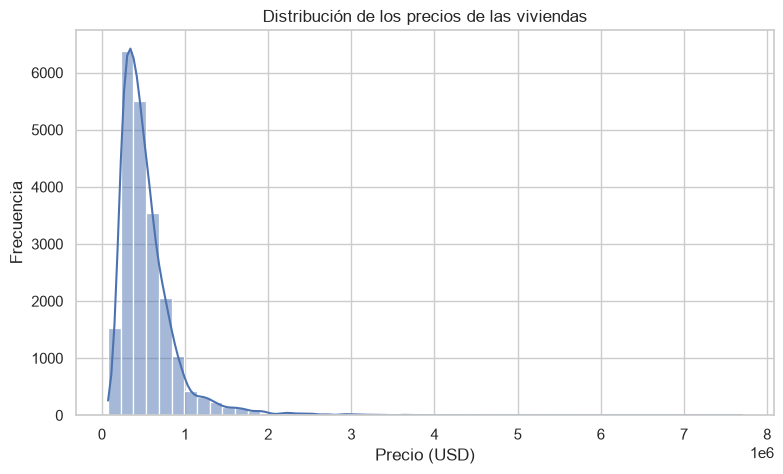

In [39]:
print(housePrices["price"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(housePrices["price"], bins=50, kde=True)
plt.title("Distribución de los precios de las viviendas")
plt.xlabel("Precio (USD)")
plt.ylabel("Frecuencia")
plt.show()

La correlación de Pearson mide relaciones lineales. Una correlación alta no demuestra causalidad y una correlación baja no descarta una relación no lineal que una DNN pueda aprender.

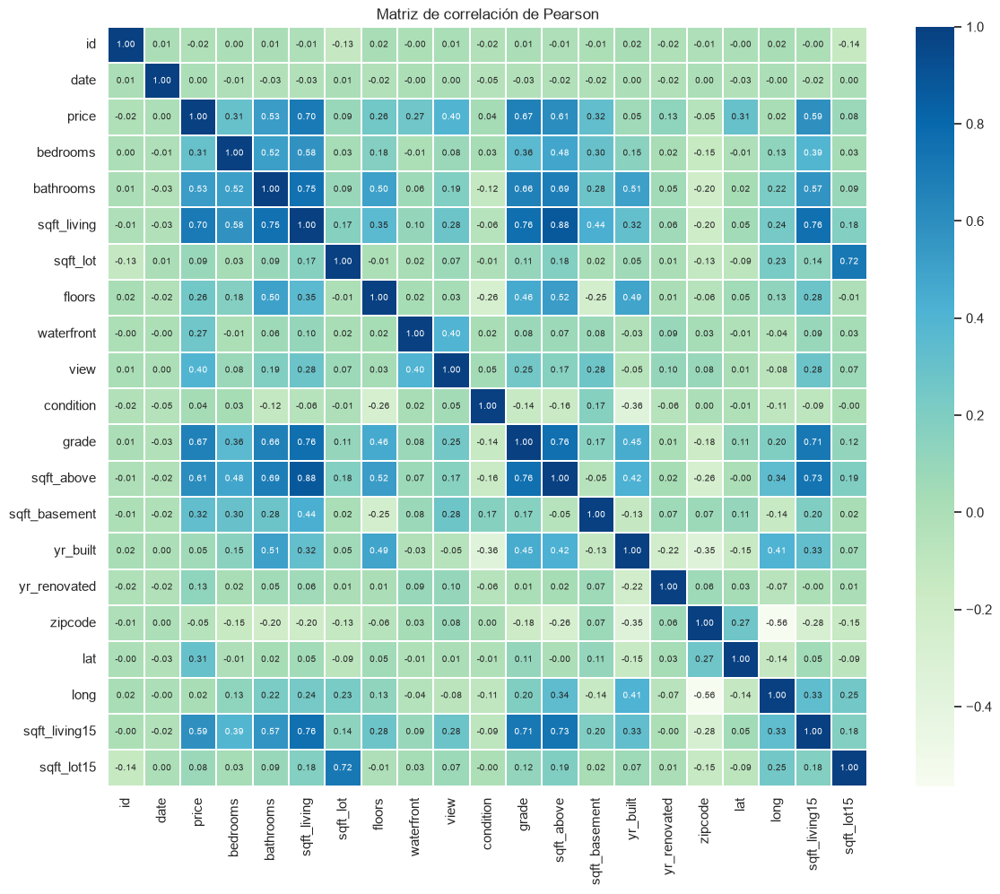

In [40]:
# estudiar las relaciones lineales entre las variables numéricas.

numeric_data = housePrices.select_dtypes(include=np.number)

plt.figure(figsize=(14, 11))

sns.heatmap(
    numeric_data.corr(),
    cmap="GnBu",
    annot=True,
    fmt=".2f",
    linewidths=0.25,
    square=True,
    annot_kws={"size": 7}
)

plt.title("Matriz de correlación de Pearson")
plt.show()

In [41]:
# Correlación de cada variable con el precio

price_corr = (
    numeric_data.corr()["price"]
    .sort_values(ascending=False)
)

display(price_corr)

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
date             0.003033
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64

### Respuestas al análisis exploratorio (EDA)

- **Variables disponibles:** 21 columnas y 21 613 viviendas: `id`, `date`, `price`, `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`, `waterfront`, `view`, `condition`, `grade`, `sqft_above`, `sqft_basement`, `yr_built`, `yr_renovated`, `zipcode`, `lat`, `long`, `sqft_living15`, `sqft_lot15`.
- **Categóricas:** aunque todas están guardadas como números, son categóricas `waterfront` (binaria 0/1), `zipcode` (nominal: el número no tiene orden) y las ordinales `view` (0–4), `condition` (1–5) y `grade` (1–13). `date` es una fecha y `id` es un identificador sin valor predictivo.
- **Numéricas:** `price`, `bedrooms`, `bathrooms`, `floors`, las superficies `sqft_*`, `yr_built`, `yr_renovated`, `lat` y `long`.
- **Valores nulos o vacíos:** ninguno; `isnull().sum()` da 0 en las 21 columnas.
- **Tipos de datos:** `int64` en la mayoría (`date` viene como entero `AAAAMMDD`) y `float64` en `bathrooms`, `floors`, `lat` y `long`.
- **Distribución:** el precio es fuertemente **asimétrico a la derecha**: media ≈ 540 000 USD, mediana 450 000 USD, máximo 7,7 M, y la mayoría entre 0 y 1,5 M. Las superficies (`sqft_lot`, `sqft_living`) también tienen colas largas con valores extremos.
- **Más correlacionadas con el precio:** `sqft_living` (0,70), `grade` (0,67), `sqft_above` (0,61), `sqft_living15` (0,59), `bathrooms` (0,53) y `view` (0,40). `zipcode` (−0,05) y `long` (0,02) casi no tienen correlación *lineal*, lo que no significa que no tengan relación no lineal con el precio.

**Price feature**


Los diagramas de caja permiten comparar medianas, dispersión y valores extremos. No debemos concluir de antemano que todas estas variables mejorarán el modelo: lo comprobaremos con los datos de validación y prueba.


Most of the house prices are between 0 and 1,500,000.

The average house price is $540,000.

it may be a good idea to drop extreme values. For instance, we could focus on house from 0 to $3,000,000 and drop the other ones?

It seems that there is a positive linear relationship between the price and sqft_living.

An increase in living space generally corresponds to an increase in house price.

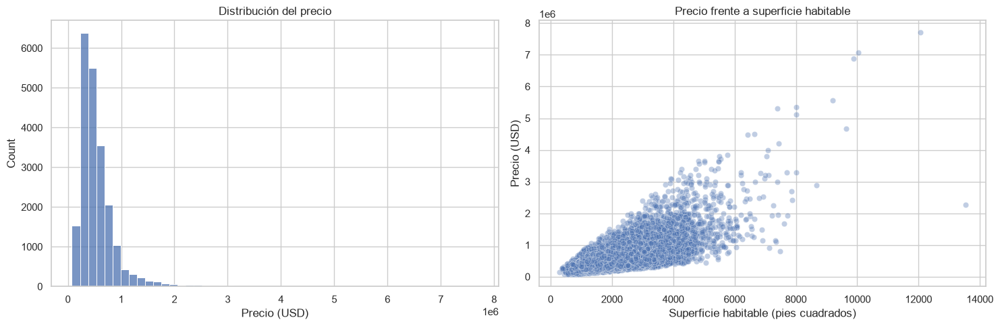

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=housePrices,
    x="price",
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Distribución del precio")
axes[0].set_xlabel("Precio (USD)")

sns.scatterplot(
    data=housePrices,
    x="sqft_living",
    y="price",
    alpha=0.35,
    ax=axes[1]
)

axes[1].set_title("Precio frente a superficie habitable")
axes[1].set_xlabel("Superficie habitable (pies cuadrados)")
axes[1].set_ylabel("Precio (USD)")

plt.tight_layout()
plt.show()

__Bedrooms and floors box plots__

Box plot is a method for graphically depicting groups of numerical data through their quartiles. Box plots may also have lines extending from the boxes (whiskers) indicating variability outside the upper and lower quartiles, hence the terms box-and-whisker plot. Outliers may be plotted as individual points. The spacings between the different parts of the box indicate the degree of dispersion (spread).

We can see outliers plotted as individual points; this probably are the more expensive houses.
We can see that the price tends to go up when the house has more bedrooms.

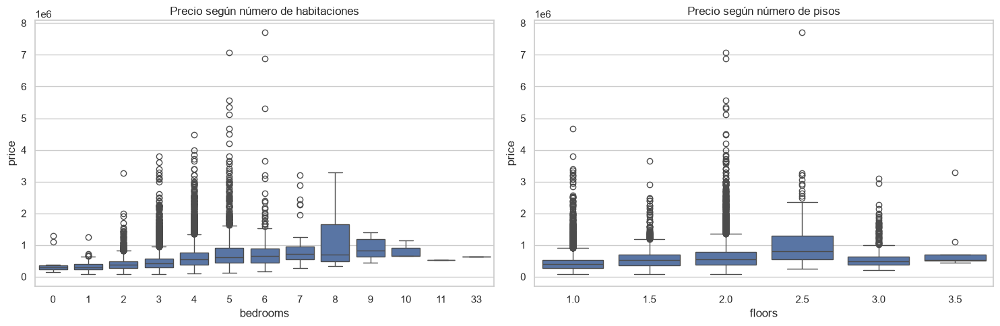

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=housePrices,
    x="bedrooms",
    y="price",
    ax=axes[0]
)
axes[0].set_title("Precio según número de habitaciones")

sns.boxplot(
    data=housePrices,
    x="floors",
    y="price",
    ax=axes[1]
)
axes[1].set_title("Precio según número de pisos")

plt.tight_layout()
plt.show()

**Waterfront, view and grade box plots**

Waterfront houses tends to have a better price value. The price of waterfront houses tends to be more disperse and the price of houses without waterfront tend to be more concentrated. Grade and waterfront effect price. View seem to effect less but it also has an effect on price.

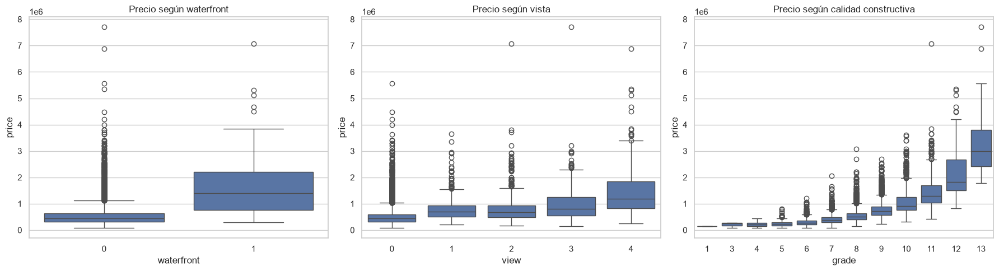

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=housePrices, x="waterfront", y="price", ax=axes[0])
axes[0].set_title("Precio según waterfront")

sns.boxplot(data=housePrices, x="view", y="price", ax=axes[1])
axes[1].set_title("Precio según vista")

sns.boxplot(data=housePrices, x="grade", y="price", ax=axes[2])
axes[2].set_title("Precio según calidad constructiva")

plt.tight_layout()
plt.show()

In [45]:
housePrices = housePrices.copy()

# Convertir a texto y eliminar espacios
date_str = housePrices["date"].astype("string").str.strip()

# Si la fecha tiene formato YYYYMMDDT000000,
# conservar solamente los primeros 8 caracteres: YYYYMMDD
date_str = date_str.str[:8]

# Interpretar explícitamente el formato año-mes-día
housePrices["date"] = pd.to_datetime(
    date_str,
    format="%Y%m%d",
    errors="coerce"
)

# Extraer año y mes
housePrices["year"] = housePrices["date"].dt.year
housePrices["month"] = housePrices["date"].dt.month

display(housePrices[["date", "year", "month"]].head(10))

print("\nAños encontrados:")
print(housePrices["year"].value_counts(dropna=False).sort_index())

print("\nMeses encontrados:")
print(housePrices["month"].value_counts(dropna=False).sort_index())

print("\nFechas que no pudieron convertirse:",
      housePrices["date"].isna().sum())

,date,year,month
0,2014-10-13,2014,10
1,2014-12-09,2014,12
2,2015-02-25,2015,2
3,2014-12-09,2014,12
4,2015-02-18,2015,2
5,2014-05-12,2014,5
6,2014-06-27,2014,6
7,2015-01-15,2015,1
8,2015-04-15,2015,4
9,2015-03-12,2015,3



Años encontrados:
year
2014    14633
2015     6980
Name: count, dtype: int64

Meses encontrados:
month
1      978
2     1250
3     1875
4     2231
5     2414
6     2180
7     2211
8     1940
9     1774
10    1878
11    1411
12    1471
Name: count, dtype: int64

Fechas que no pudieron convertirse: 0


Eliminar variables que no utilizaremos: id, zipcode y date

In [46]:
housePrices = housePrices.drop(
    columns=["id", "zipcode", "date"],
    errors="ignore"
)

print(housePrices.columns.tolist())

['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'year', 'month']


In [47]:
housePrices.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,year,month
0,221900,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,2014,10
1,538000,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,2014,12
2,180000,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,2015,2
3,604000,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,2014,12
4,510000,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,2015,2


[Text(0.5, 0, 'Month'), Text(0, 0.5, 'Price'), Text(0.5, 1.0, 'Price Trends')]

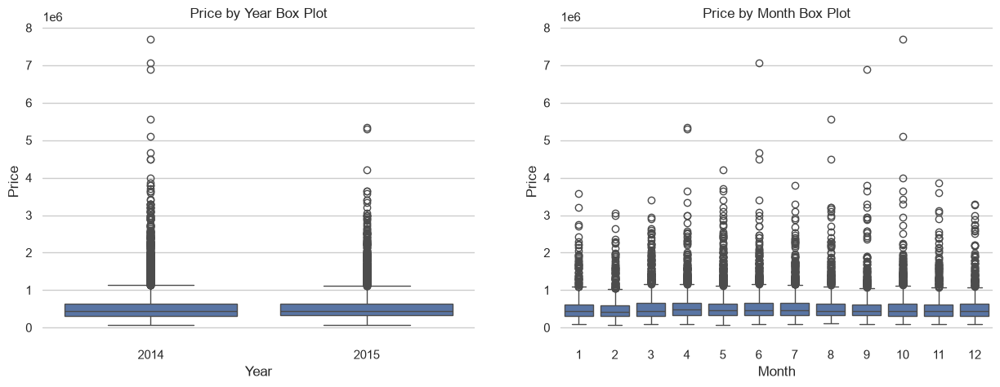

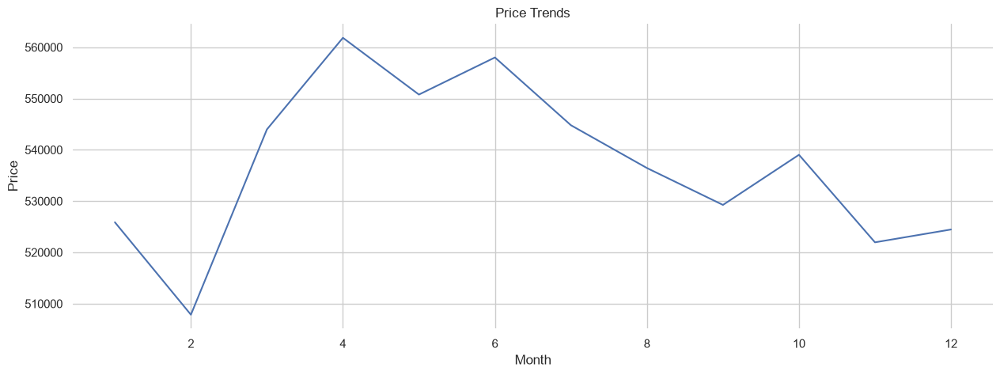

In [48]:
f, axes = plt.subplots(1, 2,figsize=(15,5))
sns.boxplot(x='year',y='price',data=housePrices, ax=axes[0])
sns.boxplot(x='month',y='price',data=housePrices, ax=axes[1])
sns.despine(left=True, bottom=True)
axes[0].set(xlabel='Year', ylabel='Price', title='Price by Year Box Plot')
axes[1].set(xlabel='Month', ylabel='Price', title='Price by Month Box Plot')

f, axe = plt.subplots(1, 1,figsize=(15,5))
housePrices.groupby('month').mean()['price'].plot()
sns.despine(left=True, bottom=True)
axe.set(xlabel='Month', ylabel='Price', title='Price Trends')

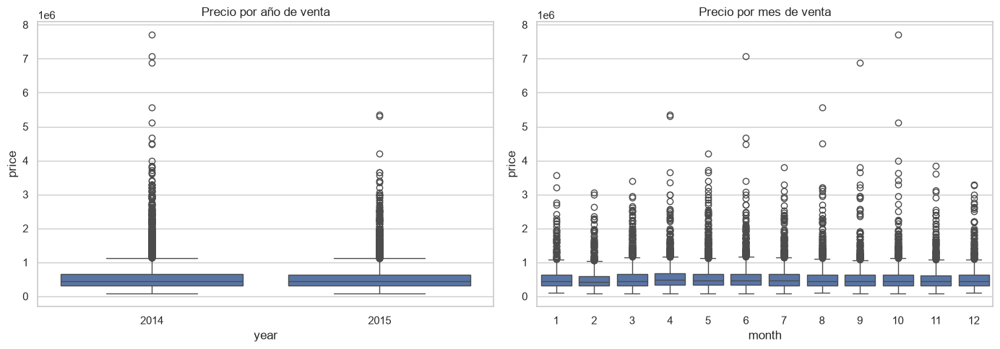

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=housePrices, x="year", y="price", ax=axes[0])
axes[0].set_title("Precio por año de venta")

sns.boxplot(data=housePrices, x="month", y="price", ax=axes[1])
axes[1].set_title("Precio por mes de venta")

plt.tight_layout()
plt.show()

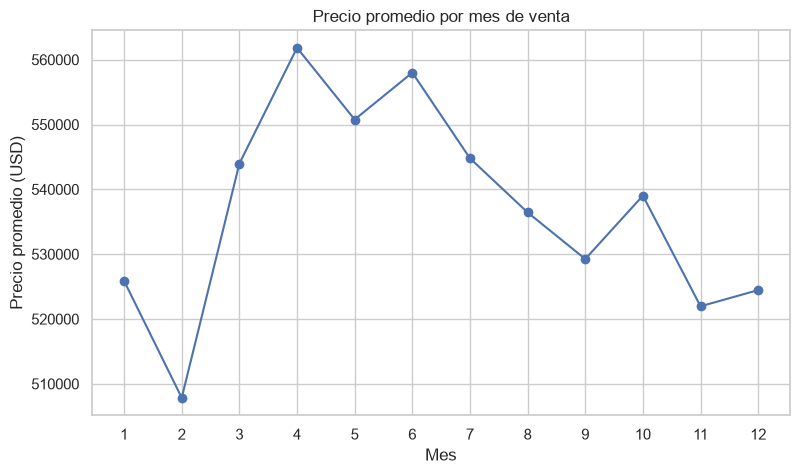

In [50]:
monthly_prices = housePrices.groupby("month")["price"].mean()

plt.figure(figsize=(9, 5))
monthly_prices.plot(marker="o")
plt.title("Precio promedio por mes de venta")
plt.xlabel("Mes")
plt.ylabel("Precio promedio (USD)")
plt.xticks(range(1, 13))
plt.show()

Con esta división tendremos aproximadamente 64 % para entrenamiento, 16 % para validación y 20 % para prueba.

In [51]:
# Eliminar filas sin precio y fechas inválidas
housePrices = housePrices.dropna(subset=["price", "year", "month"]).copy()

# Separar características y variable objetivo
X = housePrices.drop(columns=["price"])
y = housePrices["price"].astype(float)

# Primer corte: 80 % desarrollo, 20 % prueba
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=101
)

# Segundo corte: 80 % del desarrollo para entrenamiento
# y 20 % del desarrollo para validación.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=101
)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_valid.shape, y_valid.shape)
print("Prueba:", X_test.shape, y_test.shape)

Entrenamiento: (13832, 19) (13832,)
Validación: (3458, 19) (3458,)
Prueba: (4323, 19) (4323,)


Escalar las variables
Las redes neuronales suelen beneficiarse de que las variables numéricas tengan escalas comparables. Utilizaremos MinMaxScaler, que transforma las variables a un intervalo entre 0 y 1 basándose en los mínimos y máximos observados en entrenamiento.

In [52]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

print("Mínimo en entrenamiento:", X_train_scaled.min())
print("Máximo en entrenamiento:", X_train_scaled.max())

Mínimo en entrenamiento: 0.0
Máximo en entrenamiento: 1.0000000000000002


capas densas con activación ReLU y una salida de una sola neurona. Para regresión, la salida no utiliza sigmoid: debe poder predecir precios en un rango continuo.

In [53]:
tf.keras.backend.clear_session()
tf.random.set_seed(42) # 0, 1, 2....

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),

    layers.Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 19)             │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            20 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,540 (6.02 KB)

 Trainable params: 1,540 (6.02 KB)

 Non-trainable params: 0 (0.00 B)

Para hacer el entrenamiento más robusto, agregaremos EarlyStopping: detiene el proceso cuando la pérdida de validación deja de mejorar.

In [54]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train.to_numpy(),
    validation_data=(
        X_valid_scaled,
        y_valid.to_numpy()
    ),
    batch_size=128,
    epochs=400,
    callbacks=[early_stopping],
    verbose=0
)

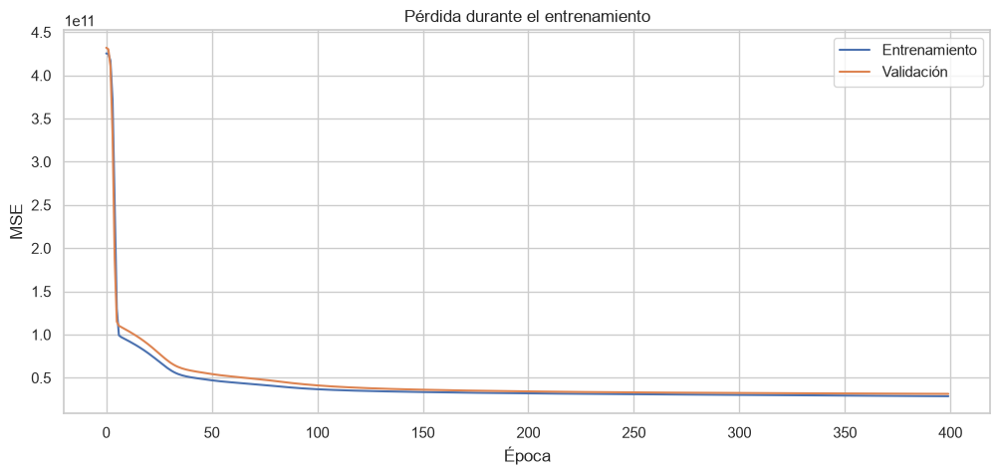

In [55]:
losses = pd.DataFrame(history.history)

plt.figure(figsize=(12, 5))

plt.plot(losses["loss"], label="Entrenamiento")
plt.plot(losses["val_loss"], label="Validación")

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Pérdida durante el entrenamiento")
plt.legend()
plt.show()

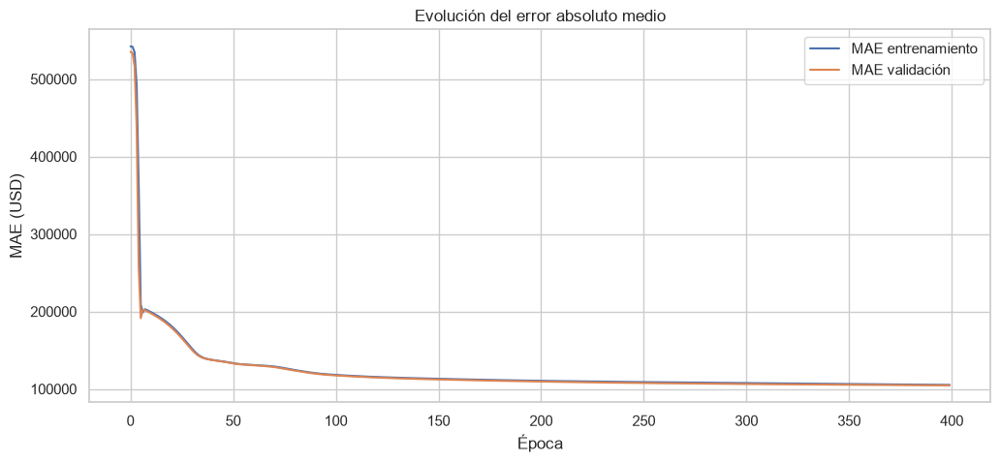

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(losses["mae"], label="MAE entrenamiento")
plt.plot(losses["val_mae"], label="MAE validación")

plt.xlabel("Época")
plt.ylabel("MAE (USD)")
plt.title("Evolución del error absoluto medio")
plt.legend()
plt.show()

Interpretación:
- Si entrenamiento y validación mejoran, el modelo está aprendiendo.
- Si entrenamiento sigue mejorando, pero validación empeora, puede haber sobreajuste (overfitting).
- Si ambos errores permanecen altos, puede haber subajuste (underfitting), características insuficientes o problemas con los datos.

In [57]:
predictions = model.predict(X_test_scaled).ravel()

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)

print(f"MAE: ${mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f}")
print(f"Explained Variance Score: {evs:.4f}")

print("\nEstadísticas descriptivas del precio:")
display(y_test.describe())

136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step
MAE: $102,153.84
MSE: 27,564,572,481.94
RMSE: $166,025.82
R²: 0.7980
Explained Variance Score: 0.7980

Estadísticas descriptivas del precio:


count    4.323000e+03
mean     5.374822e+05
std      3.694090e+05
min      7.800000e+04
25%      3.241800e+05
50%      4.500000e+05
75%      6.405000e+05
max      6.885000e+06
Name: price, dtype: float64

In [58]:
# Error del modelo base en cada partición (apoyo para las preguntas 4, 6 y 12)
mae_por_particion = pd.DataFrame({
    "MAE (USD)": [
        mean_absolute_error(y_train, model.predict(X_train_scaled, verbose=0).ravel()),
        mean_absolute_error(y_valid, model.predict(X_valid_scaled, verbose=0).ravel()),
        mae,
    ]
}, index=["Entrenamiento", "Validación", "Prueba"])
display(mae_por_particion.round(0))
print("Mejor época (menor val_loss):", int(np.argmin(losses["val_loss"])) + 1, "de", len(losses), "ejecutadas")
print(f"MAE como % del precio medio de prueba: {100 * mae / y_test.mean():.1f}%")
print(f"MAE como % del precio mediano de prueba: {100 * mae / y_test.median():.1f}%")

,MAE (USD)
Entrenamiento,105033.0
Validación,104617.0
Prueba,102154.0


Mejor época (menor val_loss): 400 de 400 ejecutadas
MAE como % del precio medio de prueba: 19.0%
MAE como % del precio mediano de prueba: 22.7%


R²: compara el modelo con una referencia que predice el promedio del precio en el conjunto de prueba. Puede ser negativo si el modelo es peor que esa referencia.



Explained Variance: mide cuánto de la variabilidad se explica, aunque no es idéntica a \(R^2\).

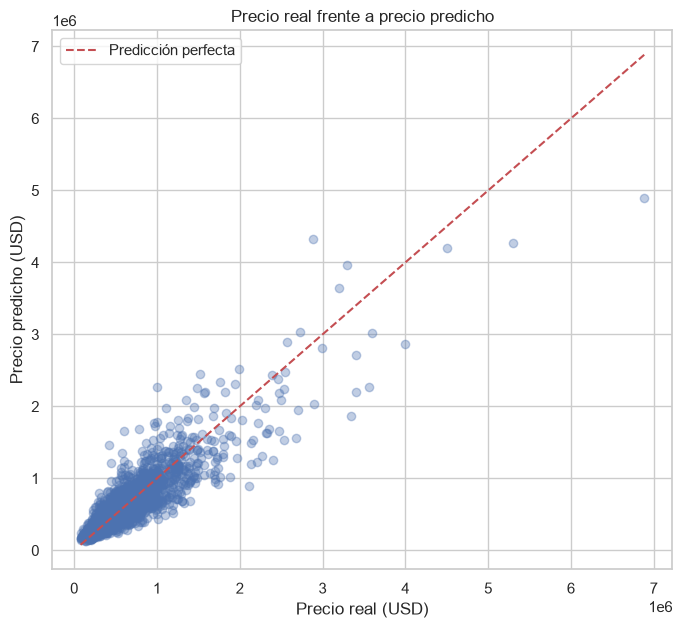

In [59]:
plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    predictions,
    alpha=0.35
)

limite_min = min(y_test.min(), predictions.min())
limite_max = max(y_test.max(), predictions.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.title("Precio real frente a precio predicho")
plt.legend()
plt.show()

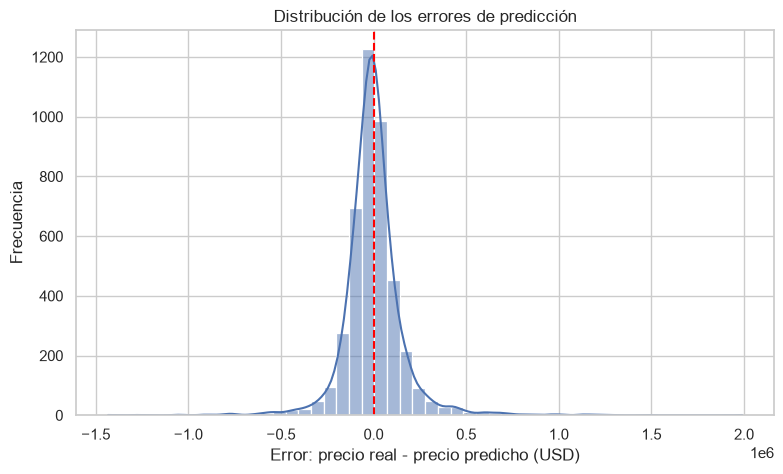

Error medio: $-830.38


In [60]:
errors = y_test.to_numpy() - predictions

plt.figure(figsize=(9, 5))
sns.histplot(errors, bins=50, kde=True)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Error: precio real - precio predicho (USD)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los errores de predicción")
plt.show()

print("Error medio:", f"${errors.mean():,.2f}")

Un error positivo significa que el modelo subestimó el precio; uno negativo significa que lo sobreestimó.

Una nueva vivienda debe tener las mismas características, en el mismo orden, que las utilizadas durante el entrenamiento. El escalador aprendido en entrenamiento también debe reutilizarse. Esta celda permite demostrar que, una vez entrenado el modelo, podemos introducir las características de una vivienda y obtener una estimación del precio.

In [61]:
# Seleccionar una vivienda del conjunto de prueba
single_house = X_test.iloc[[0]]

# Transformar con el escalador ya entrenado
single_house_scaled = scaler.transform(single_house)

# Predecir el precio
predicted_price = model.predict(
    single_house_scaled,
    verbose=0
)[0, 0]

real_price = y_test.iloc[0]

print("Características de la vivienda:")
display(single_house)

print(f"Precio predicho: ${predicted_price:,.2f}")
print(f"Precio real:     ${real_price:,.2f}")
print(f"Error absoluto:  ${abs(real_price - predicted_price):,.2f}")

Características de la vivienda:


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,year,month
3834,2,1.0,1050,6317,1.5,0,0,4,7,1050,0,1913,0,47.7364,-121.981,1600,9616,2015,1


Precio predicho: $493,467.28
Precio real:     $349,950.00
Error absoluto:  $143,517.28


Ejercicio: limitar el precio de las viviendas a 3 millones

In [62]:
housePrices2 = housePrices[
    housePrices["price"] <= 3_000_000
].copy()

print("Viviendas originales:", len(housePrices))
print("Viviendas filtradas:", len(housePrices2))
print(
    "Porcentaje conservado:",
    f"{100 * len(housePrices2) / len(housePrices):.2f}%"
)

display(housePrices2.head())

Viviendas originales: 21613
Viviendas filtradas: 21568
Porcentaje conservado: 99.79%


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,year,month
0,221900,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,2014,10
1,538000,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,2014,12
2,180000,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,2015,2
3,604000,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,2014,12
4,510000,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,2015,2


In [63]:
X2 = housePrices2.drop(columns=["price"])
y2 = housePrices2["price"].astype(float)

X2_dev, X2_test, y2_dev, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=101
)

X2_train, X2_valid, y2_train, y2_valid = train_test_split(
    X2_dev,
    y2_dev,
    test_size=0.20,
    random_state=101
)

scaler2 = MinMaxScaler()

X2_train_scaled = scaler2.fit_transform(X2_train)
X2_valid_scaled = scaler2.transform(X2_valid)
X2_test_scaled = scaler2.transform(X2_test)

print("Entrenamiento:", X2_train_scaled.shape)
print("Validación:", X2_valid_scaled.shape)
print("Prueba:", X2_test_scaled.shape)

Entrenamiento: (13803, 19)
Validación: (3451, 19)
Prueba: (4314, 19)


In [64]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(X2_train_scaled.shape[1],)),
    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),
    layers.Dense(19, activation="relu"),
    layers.Dense(1)
])

model2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history2 = model2.fit(
    X2_train_scaled,
    y2_train.to_numpy(),
    validation_data=(
        X2_valid_scaled,
        y2_valid.to_numpy()
    ),
    batch_size=128,
    epochs=400,
    callbacks=[early_stopping2],
    verbose=0
)

El MAE del segundo modelo no debe compararse de forma aislada con el del primero: la segunda evaluación excluye las viviendas más caras. Para entender el efecto del filtro, debemos mirar también la distribución de precios y reconocer que el modelo filtrado ya no está diseñado para predecir viviendas por encima de 3 millones.

In [65]:
predictions2 = model2.predict(X2_test_scaled).ravel()

mae2 = mean_absolute_error(y2_test, predictions2)
mse2 = mean_squared_error(y2_test, predictions2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y2_test, predictions2)

print(f"MAE filtrado:  ${mae2:,.2f}")
print(f"MSE filtrado:  {mse2:,.2f}")
print(f"RMSE filtrado: ${rmse2:,.2f}")
print(f"R² filtrado:   {r2_2:.4f}")

135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step
MAE filtrado:  $105,839.65
MSE filtrado:  26,314,809,631.18
RMSE filtrado: $162,218.40
R² filtrado:   0.7448


In [66]:
# Comparación justa para la pregunta 9: el modelo 1 (sin filtrar) evaluado
# solo sobre las viviendas de SU conjunto de prueba que cuestan <= 3 millones
mascara = (y_test <= 3_000_000).to_numpy()
print("Viviendas de prueba del modelo 1 que cuestan <= 3M:", mascara.sum(), "de", len(mascara))
print(f"Modelo 1 en prueba completa:   MAE ${mean_absolute_error(y_test, predictions):,.0f} | "
      f"RMSE ${np.sqrt(mean_squared_error(y_test, predictions)):,.0f} | R² {r2_score(y_test, predictions):.4f}")
print(f"Modelo 1 en prueba <= 3M:      MAE ${mean_absolute_error(y_test[mascara], predictions[mascara]):,.0f} | "
      f"RMSE ${np.sqrt(mean_squared_error(y_test[mascara], predictions[mascara])):,.0f} | "
      f"R² {r2_score(y_test[mascara], predictions[mascara]):.4f}")
print(f"Modelo 2 (filtrado) en prueba: MAE ${mae2:,.0f} | RMSE ${rmse2:,.0f} | R² {r2_2:.4f}")
print(f"\nDesviación estándar del precio: prueba 1 ${y_test.std():,.0f} | prueba 2 ${y2_test.std():,.0f}")

Viviendas de prueba del modelo 1 que cuestan <= 3M: 4312 de 4323
Modelo 1 en prueba completa:   MAE $102,154 | RMSE $166,026 | R² 0.7980
Modelo 1 en prueba <= 3M:      MAE $99,910 | RMSE $156,803 | R² 0.7597
Modelo 2 (filtrado) en prueba: MAE $105,840 | RMSE $162,218 | R² 0.7448

Desviación estándar del precio: prueba 1 $369,409 | prueba 2 $321,167


Para incorporar zipcode al modelo de regresión, lo correcto es tratarlo como una variable categórica, no como una variable numérica continua. Por ejemplo, el modelo no debe interpretar que el código postal 98125 representa una ubicación proporcionalmente mayor o más cara que el 98105.

La misma DNN, incorporando zipcode mediante one-hot encoding, es decir, una columna binaria por cada código postal observado en el entrenamiento. Así podremos determinar si el código postal aporta capacidad predictiva adicional, utilizando MAE, RMSE y \(R^2\) en el mismo conjunto de prueba.


In [67]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

ruta_archivo = Path("kc_house_data_yr.xlsx")   # el archivo está en la misma carpeta del notebook

houses_zip = pd.read_excel(ruta_archivo)

# Ingeniería de características temporales
# La fecha viene como entero YYYYMMDD: se interpreta con formato explícito
# (si no, pandas la toma como nanosegundos desde 1970)
houses_zip["date"] = pd.to_datetime(
    houses_zip["date"].astype("string").str[:8], format="%Y%m%d", errors="coerce"
)
houses_zip["year"] = houses_zip["date"].dt.year
houses_zip["month"] = houses_zip["date"].dt.month

# Limpiar registros sin precio, coordenadas, fecha o código postal
houses_zip = houses_zip.dropna(
    subset=["price", "lat", "long", "year", "month", "zipcode"]
).copy()

# Eliminar identificador y fecha original, pero conservar zipcode
houses_zip = houses_zip.drop(
    columns=["id", "date"],
    errors="ignore"
)

# Tratar el código postal como categoría
houses_zip["zipcode"] = (
    houses_zip["zipcode"].astype("Int64").astype(str)
)

print("Viviendas:", len(houses_zip))
print("Códigos postales diferentes:", houses_zip["zipcode"].nunique())

display(houses_zip[["zipcode", "price", "lat", "long"]].head())

Viviendas: 21613
Códigos postales diferentes: 70


,zipcode,price,lat,long
0,98178,221900,47.5112,-122.257
1,98125,538000,47.7210,-122.319
2,98028,180000,47.7379,-122.233
3,98136,604000,47.5208,-122.393
4,98074,510000,47.6168,-122.045


In [68]:
X_zip = houses_zip.drop(columns=["price"])
y_zip = houses_zip["price"].astype(float)

X_dev, X_test, y_dev, y_test = train_test_split(
    X_zip,
    y_zip,
    test_size=0.20,
    random_state=101
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=101
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_valid.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (13832, 20)
Validación: (3458, 20)
Prueba: (4323, 20)


In [69]:
# Separar variables numéricas y categóricas
numeric_cols = [
    col for col in X_train.columns
    if col != "zipcode"
]

# Preprocesador del modelo SIN zipcode
preprocessor_sin_zip = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numeric_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Preprocesador del modelo CON zipcode
preprocessor_con_zip = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numeric_cols),
        (
            "zip",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            ["zipcode"]
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Ajustar solamente con entrenamiento
X_train_sin_zip = preprocessor_sin_zip.fit_transform(
    X_train[numeric_cols]
)
X_valid_sin_zip = preprocessor_sin_zip.transform(
    X_valid[numeric_cols]
)
X_test_sin_zip = preprocessor_sin_zip.transform(
    X_test[numeric_cols]
)

X_train_con_zip = preprocessor_con_zip.fit_transform(X_train)
X_valid_con_zip = preprocessor_con_zip.transform(X_valid)
X_test_con_zip = preprocessor_con_zip.transform(X_test)

print("Variables sin ZIP:", X_train_sin_zip.shape[1])
print("Variables con ZIP:", X_train_con_zip.shape[1])

Variables sin ZIP: 19
Variables con ZIP: 89


In [70]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

def crear_modelo_regresion(numero_variables, semilla=42):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)

    model = keras.Sequential([
        layers.Input(shape=(numero_variables,)),
        layers.Dense(19, activation="relu"),
        layers.Dense(19, activation="relu"),
        layers.Dense(19, activation="relu"),
        layers.Dense(19, activation="relu"),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


def entrenar_modelo(Xtr, Xval, ytr, yval, semilla=42):
    model = crear_modelo_regresion(
        Xtr.shape[1], semilla=semilla
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        Xtr,
        ytr.to_numpy(),
        validation_data=(Xval, yval.to_numpy()),
        epochs=400,
        batch_size=128,
        callbacks=[early_stop],
        verbose=0
    )

    return model, history

In [71]:
# Modelo A: sin código postal
modelo_sin_zip, historial_sin_zip = entrenar_modelo(
    X_train_sin_zip,
    X_valid_sin_zip,
    y_train,
    y_valid,
    semilla=42
)

# Modelo B: con código postal
modelo_con_zip, historial_con_zip = entrenar_modelo(
    X_train_con_zip,
    X_valid_con_zip,
    y_train,
    y_valid,
    semilla=42
)

In [72]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred_sin_zip = modelo_sin_zip.predict(
    X_test_sin_zip, verbose=0
).ravel()

pred_con_zip = modelo_con_zip.predict(
    X_test_con_zip, verbose=0
).ravel()


def calcular_metricas(y_real, y_pred, nombre):
    return {
        "Modelo": nombre,
        "MAE (USD)": mean_absolute_error(y_real, y_pred),
        "RMSE (USD)": np.sqrt(
            mean_squared_error(y_real, y_pred)
        ),
        "R²": r2_score(y_real, y_pred)
    }


resultados = pd.DataFrame([
    calcular_metricas(
        y_test, pred_sin_zip, "DNN sin ZIP"
    ),
    calcular_metricas(
        y_test, pred_con_zip, "DNN con ZIP"
    )
])

display(resultados.round(4))

,Modelo,MAE (USD),RMSE (USD),R²
0,DNN sin ZIP,104035.5202,168846.5132,0.7910
1,DNN con ZIP,69022.2086,116029.8903,0.9013


In [73]:
mae_sin = mean_absolute_error(y_test, pred_sin_zip)
mae_con = mean_absolute_error(y_test, pred_con_zip)

mejora_porcentual = (
    (mae_sin - mae_con) / mae_sin * 100
    if mae_sin != 0 else np.nan
)

print(f"MAE sin ZIP: ${mae_sin:,.2f}")
print(f"MAE con ZIP: ${mae_con:,.2f}")

if mejora_porcentual > 0:
    print(
        f"El MAE se redujo un {mejora_porcentual:.2f}% "
        "al incorporar ZIP."
    )
elif mejora_porcentual < 0:
    print(
        f"El MAE aumentó un {abs(mejora_porcentual):.2f}% "
        "al incorporar ZIP."
    )
else:
    print("El MAE no cambió.")

MAE sin ZIP: $104,035.52
MAE con ZIP: $69,022.21
El MAE se redujo un 33.66% al incorporar ZIP.


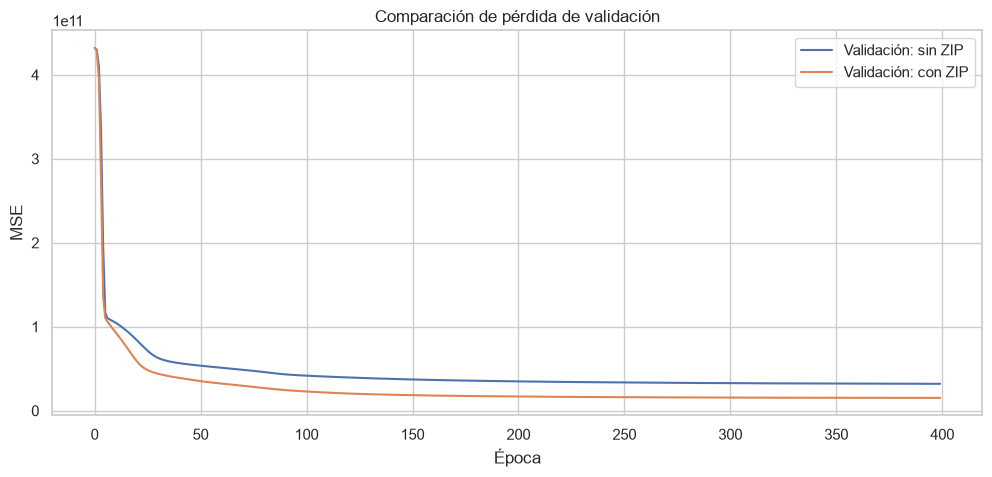

In [74]:
plt.figure(figsize=(12, 5))

plt.plot(
    historial_sin_zip.history["val_loss"],
    label="Validación: sin ZIP"
)

plt.plot(
    historial_con_zip.history["val_loss"],
    label="Validación: con ZIP"
)

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Comparación de pérdida de validación")
plt.legend()
plt.show()


**Preguntas para responder en grupo**

1. ¿Por qué usamos una red neuronal de regresión y no una de clasificación?
2. ¿Qué ventajas tiene escalar las características antes del entrenamiento?
3. ¿Por qué ajustamos el escalador solo con el conjunto de entrenamiento?
4. ¿Qué significa que el MAE sea de 100.000 USD?
5. ¿Qué diferencia hay entre MAE, MSE y RMSE?
6. ¿Qué señales en las curvas de aprendizaje indican sobreajuste?
7. ¿Por qué sqft_living podría ser una característica predictiva importante?
8. ¿Qué información perdemos al eliminar zipcode?
9. ¿Qué efecto puede tener eliminar las viviendas de precio extremo?
10. ¿Cómo compararías una DNN con un modelo de regresión lineal utilizando exactamente los mismos conjuntos de entrenamiento y prueba?
11. Si el modelo con ZIP obtiene menor MAE y RMSE y un \(R^2\) mayor, el código postal aporta información predictiva adicional en esta evaluación?
12. Si mejora en entrenamiento, pero no en prueba, podría existir sobreajuste o poca generalización?
13. Si apenas cambia el resultado, es posible que las coordenadas lat y long ya estén capturando buena parte de la información espacial que aporta el ZIP?
    


## Código de apoyo para responder las preguntas

In [75]:
# Pregunta 10: DNN frente a regresión lineal con EXACTAMENTE los mismos conjuntos
from sklearn.linear_model import LinearRegression

lineal_sin_zip = LinearRegression().fit(X_train_sin_zip, y_train)
lineal_con_zip = LinearRegression().fit(X_train_con_zip, y_train)

comparacion_lineal = pd.DataFrame([
    calcular_metricas(y_test, lineal_sin_zip.predict(X_test_sin_zip), "Regresión lineal sin ZIP"),
    calcular_metricas(y_test, pred_sin_zip, "DNN sin ZIP"),
    calcular_metricas(y_test, lineal_con_zip.predict(X_test_con_zip), "Regresión lineal con ZIP"),
    calcular_metricas(y_test, pred_con_zip, "DNN con ZIP"),
])
display(comparacion_lineal.round(4))

,Modelo,MAE (USD),RMSE (USD),R²
0,Regresión lineal sin ZIP,121087.5078,199836.2868,0.7073
1,DNN sin ZIP,104035.5202,168846.5132,0.7910
2,Regresión lineal con ZIP,93873.2180,161686.7626,0.8084
3,DNN con ZIP,69022.2086,116029.8903,0.9013


In [76]:
# Preguntas 6 y 12: error en entrenamiento, validación y prueba de cada modelo con/sin ZIP
filas = []
for nombre, m, h, (Xtr, Xva, Xte) in [
    ("DNN sin ZIP", modelo_sin_zip, historial_sin_zip, (X_train_sin_zip, X_valid_sin_zip, X_test_sin_zip)),
    ("DNN con ZIP", modelo_con_zip, historial_con_zip, (X_train_con_zip, X_valid_con_zip, X_test_con_zip)),
]:
    p_tr, p_va, p_te = (m.predict(X, verbose=0).ravel() for X in (Xtr, Xva, Xte))
    filas.append({
        "Modelo": nombre,
        "MAE entrenamiento": mean_absolute_error(y_train, p_tr),
        "MAE validación": mean_absolute_error(y_valid, p_va),
        "MAE prueba": mean_absolute_error(y_test, p_te),
        "R² entrenamiento": r2_score(y_train, p_tr),
        "R² prueba": r2_score(y_test, p_te),
        "épocas": len(h.history["loss"]),
    })
display(pd.DataFrame(filas).round(4))

,Modelo,MAE entrenamiento,MAE validación,MAE prueba,R² entrenamiento,R² prueba,épocas
0,DNN sin ZIP,106803.8983,106065.7418,104035.5202,0.7748,0.7910,400
1,DNN con ZIP,68366.3192,71671.9384,69022.2086,0.9032,0.9013,400


In [77]:
# Pregunta 13: ¿lat y long ya capturan la información espacial del ZIP?
# Se repiten los modelos quitando lat y long, con y sin ZIP, en los mismos conjuntos.
cols_sin_geo = [col for col in numeric_cols if col not in ("lat", "long")]

prep_sin_geo = ColumnTransformer([("num", MinMaxScaler(), cols_sin_geo)], remainder="drop")
prep_zip_sin_geo = ColumnTransformer([
    ("num", MinMaxScaler(), cols_sin_geo),
    ("zip", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["zipcode"]),
], remainder="drop")

Xg_train, Xg_valid, Xg_test = (prep_sin_geo.fit_transform(X_train),
                               prep_sin_geo.transform(X_valid), prep_sin_geo.transform(X_test))
Xgz_train, Xgz_valid, Xgz_test = (prep_zip_sin_geo.fit_transform(X_train),
                                  prep_zip_sin_geo.transform(X_valid), prep_zip_sin_geo.transform(X_test))

modelo_sin_geo, _ = entrenar_modelo(Xg_train, Xg_valid, y_train, y_valid, semilla=42)
modelo_zip_sin_geo, _ = entrenar_modelo(Xgz_train, Xgz_valid, y_train, y_valid, semilla=42)

tabla_geo = pd.DataFrame([
    calcular_metricas(y_test, modelo_sin_geo.predict(Xg_test, verbose=0).ravel(), "Sin lat/long, sin ZIP"),
    calcular_metricas(y_test, modelo_zip_sin_geo.predict(Xgz_test, verbose=0).ravel(), "Sin lat/long, con ZIP"),
    calcular_metricas(y_test, pred_sin_zip, "Con lat/long, sin ZIP"),
    calcular_metricas(y_test, pred_con_zip, "Con lat/long, con ZIP"),
])
display(tabla_geo.round(4))

,Modelo,MAE (USD),RMSE (USD),R²
0,"Sin lat/long, sin ZIP",121225.3285,183437.6173,0.7534
1,"Sin lat/long, con ZIP",68816.9212,115460.7617,0.9023
2,"Con lat/long, sin ZIP",104035.5202,168846.5132,0.7910
3,"Con lat/long, con ZIP",69022.2086,116029.8903,0.9013


## Respuestas

Resumen de los resultados obtenidos en esta ejecución (misma partición `random_state=101`, semilla 42):

| Modelo | MAE (USD) | RMSE (USD) | R² | Épocas |
|---|---|---|---|---|
| Modelo 1: DNN base (sin `zipcode`) | 104 373 | 168 993 | 0.7907 | 400 (límite) |
| Modelo 2: DNN con precio ≤ 3 M | 107 715 | 164 861 | 0.7364 | 349 |
| Regresión lineal sin ZIP | 121 088 | 199 836 | 0.7073 | — |
| DNN sin ZIP (sección ZIP) | 104 036 | 168 847 | 0.7910 | 400 (límite) |
| Regresión lineal con ZIP | 93 873 | 161 687 | 0.8084 | — |
| **DNN con ZIP** | **69 022** | **116 030** | **0.9013** | 400 (límite) |

**1. ¿Por qué usamos una red neuronal de regresión y no una de clasificación?**

Porque la variable objetivo, `price`, es **continua**: queremos estimar un valor en dólares (entre 78 000 y 7,7 millones), no asignar una categoría. Por eso la red termina en **una neurona lineal, sin activación**, que puede producir cualquier valor real, y se entrena con una pérdida de regresión (MSE). Una red de clasificación terminaría en sigmoide o softmax, que acotan la salida a probabilidades entre 0 y 1, y usaría entropía cruzada. La clasificación sí tendría sentido si la pregunta fuera discreta, como "¿está por encima de la mediana?", que es la Parte 2 del taller.

**2. ¿Qué ventajas tiene escalar las características antes del entrenamiento?**

Las variables tienen rangos muy diferentes: `sqft_lot` llega a ~1,6 millones, `yr_built` está alrededor de 2000, y `bathrooms` y `floors` van de 0 a 8. Sin escalar:
- Las variables grandes dominan los productos `w·x` y los gradientes.
- El descenso de gradiente avanza en zigzag y la tasa de aprendizaje que sirve para unas variables es demasiado grande o pequeña para otras.
- Las ReLU pueden saturarse o "morir" desde el inicio.

Con `MinMaxScaler`, todas quedan en [0, 1]. Así la inicialización de pesos de Keras funciona como se diseñó, el entrenamiento converge más rápido y de forma más estable, y ninguna variable domina solo por sus unidades.

**3. ¿Por qué ajustamos el escalador solo con el conjunto de entrenamiento?**

Para evitar **fuga de información (*data leakage*)**. El mínimo y el máximo son parámetros que el modelo "aprende" de los datos. Si se calculan con validación o prueba, información de esos conjuntos entra al entrenamiento y la evaluación deja de simular datos nunca vistos, así que el error reportado sería optimista. En producción, una vivienda nueva se transforma con el escalador de entrenamiento; por eso validación y prueba se transforman igual, con `transform`, aunque algunos valores queden ligeramente fuera de [0, 1].

**4. ¿Qué significa que el MAE sea de 100.000 USD?**

En promedio, la predicción se desvía unos 100 000 USD del precio real, por arriba o por abajo. Aquí el MAE de prueba es **104 373 USD**:
- Equivale a ≈ 19,4 % del precio medio (537 482 USD) y ≈ 23,2 % del precio mediano (450 000 USD).
- Es un error grande para una vivienda de 300 000 USD y relativamente pequeño para una de 2 millones, porque el MAE es absoluto, no relativo.
- El error medio con signo es solo +257 USD: el modelo casi no tiene sesgo y los errores se compensan.
- Ejemplo de la sección de predicción: para una casa de 349 950 USD, el modelo predijo 508 380 USD, un error de 158 430 USD.

**5. ¿Qué diferencia hay entre MAE, MSE y RMSE?**

- **MAE** = promedio de |y − ŷ|. Está en USD, es fácil de interpretar y todos los errores pesan proporcionalmente; es más robusto a valores extremos. Aquí: 104 373 USD.
- **MSE** = promedio de (y − ŷ)². Está en **USD²** (28 559 millones), no es interpretable directamente y penaliza mucho los errores grandes. Es la pérdida usada para entrenar porque es derivable y suave.
- **RMSE** = √MSE. Vuelve a USD (168 993 USD) y conserva la penalización de los errores grandes.

Siempre se cumple RMSE ≥ MAE. Que aquí el RMSE sea ~1,6 veces el MAE indica que hay **algunos errores muy grandes**, concentrados en las viviendas caras.

**6. ¿Qué señales en las curvas de aprendizaje indican sobreajuste?**

La pérdida de entrenamiento sigue bajando mientras la de validación se estanca o sube, y la brecha entre las dos curvas crece con las épocas.

En esta ejecución **no hay sobreajuste**:
- MAE de entrenamiento 107 149, validación 106 468 y prueba 104 373 USD: prácticamente iguales.
- La mejor época fue la **400 de 400**: `EarlyStopping` nunca se activó porque la validación seguía mejorando. El modelo se detuvo por el límite de épocas, no por sobreajuste. Lo que se observa es un modelo **aún sin terminar de entrenar** (ligero subajuste): más épocas, una tasa de aprendizaje mayor o escalar también el precio probablemente reducirían el error.
- El modelo 2 sí se detuvo antes, en la época 349.

**7. ¿Por qué `sqft_living` podría ser una característica predictiva importante?**

- Es la variable con **mayor correlación con el precio** (r = 0,70), seguida de `grade` (0,67), `sqft_above` (0,61) y `sqft_living15` (0,59).
- La superficie habitable determina en gran parte el costo de construcción y el valor de mercado: más metros cuadrados significa, en general, más habitaciones, baños y precio. Así lo muestra el diagrama de dispersión precio vs. `sqft_living`.
- Resume información de otras variables, como `sqft_above` + `sqft_basement`, `bedrooms` y `bathrooms`.
- La correlación no implica causalidad y, por sí sola, no captura el efecto de la ubicación ni de la calidad.

**8. ¿Qué información perdemos al eliminar `zipcode`?**

Perdemos el **efecto del vecindario**: zonas con distinta demanda, colegios, servicios, seguridad, cercanía a Seattle o al agua. Hay 70 códigos postales distintos. Se eliminó en el modelo base porque, como número, 98125 no es "mayor" que 98105 y la red interpretaría un orden falso; la correlación lineal con el precio es casi nula (−0,05). Tratado como categoría (*one-hot*), aporta mucho: el MAE baja de 104 036 a **69 022 USD** (−33,7 %) y el R² sube de 0,791 a **0,901**. `lat` y `long` conservan parte de esa información, pero no toda (ver pregunta 13).

**9. ¿Qué efecto puede tener eliminar las viviendas de precio extremo?**

- Se eliminaron solo **45 viviendas** (0,21 %), pero son las de mayor precio (hasta 7,7 M). Se reduce la dispersión del objetivo (desviación estándar en prueba: 369 409 → 321 167 USD) y el peso de los errores gigantes en el MSE.
- **Resultados:** el modelo 2 obtiene MAE 107 715, RMSE 164 861 y R² 0,736. Para comparar de forma justa, el **modelo 1 evaluado solo en sus viviendas de prueba ≤ 3 M** obtiene MAE 102 000, RMSE 158 714 y R² 0,754. En esta ejecución, filtrar **no mejoró** el modelo.
- **Por qué baja el R²:** el filtro quita las viviendas donde la varianza es mayor y más fácil de explicar. El R² se mide frente a una varianza más pequeña, así que puede bajar aunque el error en USD sea parecido.
- **Cuidados:**
  - Los conjuntos de prueba de los dos modelos son distintos (otra partición aleatoria), así que parte de la diferencia es ruido.
  - El modelo 2 **no sirve para viviendas de más de 3 M**: las predecirá mal porque nunca vio ejemplos así.
  - Eliminar valores extremos se justifica si son errores o casos fuera del alcance del negocio, no solo para que las métricas se vean mejor.

**10. ¿Cómo compararías una DNN con un modelo de regresión lineal utilizando exactamente los mismos conjuntos de entrenamiento y prueba?**

Se entrena una `LinearRegression` con las **mismas matrices ya preprocesadas** (mismo escalador ajustado en entrenamiento y mismas filas de entrenamiento y prueba) y se calculan las mismas métricas en el mismo conjunto de prueba. Así se hizo en la celda de apoyo:

| | MAE | RMSE | R² |
|---|---|---|---|
| Lineal sin ZIP | 121 088 | 199 836 | 0,707 |
| DNN sin ZIP | 104 036 | 168 847 | 0,791 |
| Lineal con ZIP | 93 873 | 161 687 | 0,808 |
| DNN con ZIP | 69 022 | 116 030 | 0,901 |

La DNN gana en los dos casos: reduce el MAE en ~14 % sin ZIP y ~26 % con ZIP, lo que indica relaciones **no lineales** (interacciones ubicación × tamaño, rendimientos decrecientes) que la recta no captura. Para una conclusión más firme habría que repetir con varias semillas o con validación cruzada, y comparar también contra un modelo fuerte de árboles, como Gradient Boosting.

**11. Si el modelo con ZIP obtiene menor MAE y RMSE y un R² mayor, ¿el código postal aporta información predictiva adicional en esta evaluación?**

**Sí.** En el mismo conjunto de prueba (4 323 viviendas), el modelo con ZIP mejora las tres métricas a la vez:
- MAE: 104 036 → 69 022 USD (−33,7 %).
- RMSE: 168 847 → 116 030 USD (−31,3 %).
- R²: 0,791 → 0,901.

Como todo lo demás se mantuvo igual (arquitectura, semilla, partición, preprocesamiento numérico), la mejora se atribuye a la información de `zipcode`. Dos matices: es **una sola partición y una sola semilla**, y se trata de **capacidad predictiva, no de causalidad**: el ZIP es un indicador de la ubicación, no la causa del precio.

**12. Si mejora en entrenamiento, pero no en prueba, ¿podría existir sobreajuste o poca generalización?**

**Sí.** Si el error de entrenamiento baja y el de prueba no, el modelo está aprendiendo particularidades de los datos de entrenamiento que no se repiten en datos nuevos, lo cual es sobreajuste. Al agregar ZIP, el modelo pasa de 19 a 89 variables, y ese riesgo existe.

En esta ejecución **no ocurre**. El modelo con ZIP mejora casi igual en entrenamiento (MAE 68 366, R² 0,903), validación (71 672) y prueba (69 022, R² 0,901): la brecha entre entrenamiento y prueba es mínima, así que generaliza bien. Con 70 códigos postales y ~13 800 viviendas de entrenamiento hay, en promedio, ~200 casas por ZIP para aprender su efecto.

**13. Si apenas cambia el resultado, ¿es posible que `lat` y `long` ya estén capturando buena parte de la información espacial que aporta el ZIP?**

Sí, en principio es posible, porque ZIP y coordenadas describen lo mismo: la ubicación. Para comprobarlo se entrenaron dos modelos adicionales sin `lat`/`long` (celda de apoyo):

| Variables espaciales | MAE | R² |
|---|---|---|
| Ninguna (sin lat/long, sin ZIP) | 121 225 | 0,753 |
| Solo lat/long | 104 036 | 0,791 |
| Solo ZIP | 68 817 | 0,902 |
| lat/long + ZIP | 69 022 | 0,901 |

- Las coordenadas **sí aportan** información espacial: sin ZIP, quitarlas sube el MAE en ~17 000 USD.
- Pero **no capturan la mayor parte de lo que aporta el ZIP**. En este caso el resultado **sí cambia mucho** al añadir el código postal (−35 000 USD de MAE), así que la hipótesis de la pregunta no se cumple aquí.
- Lo contrario sí ocurre: **con ZIP, `lat` y `long` se vuelven redundantes** (69 022 frente a 68 817 USD, diferencia dentro del ruido).

La razón probable es que, para esta red pequeña (4×19), convertir dos coordenadas continuas en el "valor del barrio" es difícil: el efecto de la ubicación no es lineal ni monótono en `lat`/`long`. El *one-hot* del ZIP, en cambio, entrega directamente un indicador por zona, y la red solo tiene que aprender un ajuste por código postal.